# ¿Cuánta energía cuesta romper una contraseña por fuerza bruta?

**Física A: Hardware e Información — Proyecto final**
Profesor: Andrés Flórez

**Integrantes:** Felipe Rojas Díaz · Alejandra Rodríguez · Samuel Fonseca

> **Pregunta.** ¿Cuánto tiempo y energía cuesta romper una contraseña de $N$ caracteres con una GPU que se calienta y reduce su frecuencia (*throttling*), cuánto cambia eso con la calidad de la refrigeración, y desde qué longitud la termodinámica hace imposible el ataque?

## 1. Introducción

Un ataque de fuerza bruta prueba todas las combinaciones posibles de una contraseña. Con un alfabeto de 95 caracteres imprimibles, una contraseña de $N$ caracteres tiene $95^N$ combinaciones. Una GPU moderna prueba cientos de miles de millones por segundo, pero cada intento es trabajo eléctrico que termina como **calor** en el chip. El chip se calienta, se protege bajando su frecuencia y el ataque se vuelve más lento y más caro.

En este notebook construimos ese modelo paso a paso: primero la dinámica térmica del chip, después el frenado, luego el costo del ataque y, al final, el límite fundamental que impone la termodinámica (principio de Landauer).

## 2. Modelo físico

### 2.1 Balance de energía del chip

Tratamos el chip y su disipador como **un solo cuerpo** a temperatura uniforme $T$, con capacidad térmica $C_{th} = m\,c$. Por la primera ley, la energía que entra (potencia eléctrica $P$) menos la que sale al ambiente por conducción cambia su temperatura:

$$
C_{th}\,\frac{dT}{dt} \;=\; P \;-\; \frac{T - T_{amb}}{R_{th}}
$$

- $P$: potencia eléctrica disipada por el chip (W). Toda termina como calor.
- $R_{th} = \dfrac{L}{kA}$: resistencia térmica entre el chip y el aire (K/W). Un buen disipador y buena pasta térmica dan un $R_{th}$ pequeño.
- $T_{amb}$: temperatura del ambiente.

Es exactamente la misma ecuación que la de un **circuito RC**: $C_{th}$ hace el papel del condensador, $R_{th}$ el de la resistencia y $P$ el de una fuente de corriente. Por eso aparece una constante de tiempo

$$
\tau = R_{th}\,C_{th}.
$$

### 2.2 Potencia y velocidad del ataque *(secciones 8 y 9)*

La potencia dinámica de un chip CMOS es $P \approx C\,V^2 f$ (cargar y descargar condensadores en cada ciclo de reloj), y la velocidad de intentos es proporcional a la frecuencia: $r \propto f$.

### 2.3 Frenado *(sección 9)*

Los chips tienen dos frenos: un **tope de potencia** y un **límite térmico**: si $T$ supera $T_{lím} \approx 83\ ^\circ\mathrm{C}$, el chip reduce $f$. Esa realimentación vuelve el sistema **no lineal**.

### 2.4 Refrigeración y límite de Landauer *(secciones 10 y 12)*

Sacar el calor $Q$ de un cuarto cuesta un trabajo $W = Q/\mathrm{COP}$ (cota de Carnot). Y por debajo de toda la tecnología, cada operación lógica irreversible cuesta al menos $k_B T \ln 2$.

### 2.5 Suposiciones

1. Temperatura uniforme en el chip y el disipador (un solo nodo térmico).
2. Temperatura ambiente constante.
3. La potencia depende solo de la frecuencia de reloj.
4. Computación irreversible (para aplicar Landauer).

## 3. Parámetros

Todos los parámetros están en una sola celda, con unidades y origen. Los valores térmicos son **estimaciones iniciales**; los contrastamos con nuestra medición propia (sección 8).

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Estilo de las gráficas (colores fijos por serie, rejilla suave)
AZUL, NARANJA, AGUA, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRIS = "#52514e"
plt.rcParams.update({
    "figure.figsize": (8, 4.5), "figure.dpi": 110, "axes.grid": True,
    "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})

# --- Parámetros de la GPU (referencia: RTX 4090) ---
P_MAX = 450.0    # W   potencia máxima de la tarjeta (especificación del fabricante)
T_AMB = 25.0     # °C  temperatura del cuarto
T_LIM = 83.0     # °C  límite a partir del cual el chip se frena (sección 9)

# --- Parámetros térmicos (estimaciones, a ajustar con datos propios) ---
C_TH = 600.0     # J/K disipador de ~0.67 kg de aluminio y cobre, c ≈ 900 J/(kg·K)
R_BUENO = 0.10   # K/W disipador bueno
R_MALO = 0.18    # K/W disipador malo (polvo, pasta térmica seca)

for nombre, R in [("bueno", R_BUENO), ("malo", R_MALO)]:
    tau = R * C_TH
    T_eq = T_AMB + P_MAX * R
    print(f"Disipador {nombre:5s}: tau = {tau:5.1f} s | T de equilibrio sin frenado = {T_eq:5.1f} °C")

Disipador bueno: tau =  60.0 s | T de equilibrio sin frenado =  70.0 °C
Disipador malo : tau = 108.0 s | T de equilibrio sin frenado = 106.0 °C


Con estos valores, el disipador bueno se estabiliza por debajo de $T_{lím}$ y nunca necesitaría frenar, mientras que el malo llegaría a más de 100 °C si no frenara. Esa diferencia es la que la sección 9 convierte en velocidad de ataque.

## 4. Método numérico: Euler explícito

Escribimos la ecuación como $\dfrac{dT}{dt} = F(t, T)$ con

$$
F(t,T) = \frac{1}{C_{th}}\left[P - \frac{T - T_{amb}}{R_{th}}\right].
$$

El método de Euler aproxima la derivada con una recta durante un paso $\Delta t$:

$$
T_{k+1} = T_k + \Delta t\; F(t_k, T_k), \qquad t_{k+1} = t_k + \Delta t .
$$

El error que se comete en cada paso es del orden de $\Delta t^2$, y como hay $t/\Delta t$ pasos, el error acumulado es del orden de $\Delta t$ (**método de primer orden**). Lo implementamos nosotros, sin usar integradores de librerías, y separado del modelo físico para poder reutilizarlo en las siguientes fases.

In [2]:
def euler(F, T0, dt, t_final):
    # Integra dT/dt = F(t, T) desde t = 0 hasta t_final con pasos dt.
    n = int(round(t_final / dt))
    t = np.arange(n + 1) * dt
    T = np.empty(n + 1)
    T[0] = T0
    for k in range(n):
        T[k + 1] = T[k] + dt * F(t[k], T[k])
    return t, T


def F_sin_frenado(R_th, P=P_MAX, C_th=C_TH, T_amb=T_AMB):
    # Lado derecho del balance de energía con potencia constante.
    def F(t, T):
        return (P - (T - T_amb) / R_th) / C_th
    return F


def T_analitica(t, R_th, P=P_MAX, C_th=C_TH, T_amb=T_AMB):
    # Solución exacta con T(0) = T_amb.
    tau = R_th * C_th
    return T_amb + P * R_th * (1 - np.exp(-t / tau))

## 5. Validación 1: comparación con la solución analítica

Sin frenado, la ecuación es lineal y tiene solución exacta. Con $T(0) = T_{amb}$:

$$
T(t) = T_{amb} + P\,R_{th}\left(1 - e^{-t/\tau}\right).
$$

Simulamos con Euler y $\Delta t = 1\ \mathrm{s}$ (mucho menor que $\tau$) para los dos disipadores y comparamos.

Disipador bueno: error máximo de Euler = 0.139 °C
Disipador malo: error máximo de Euler = 0.138 °C


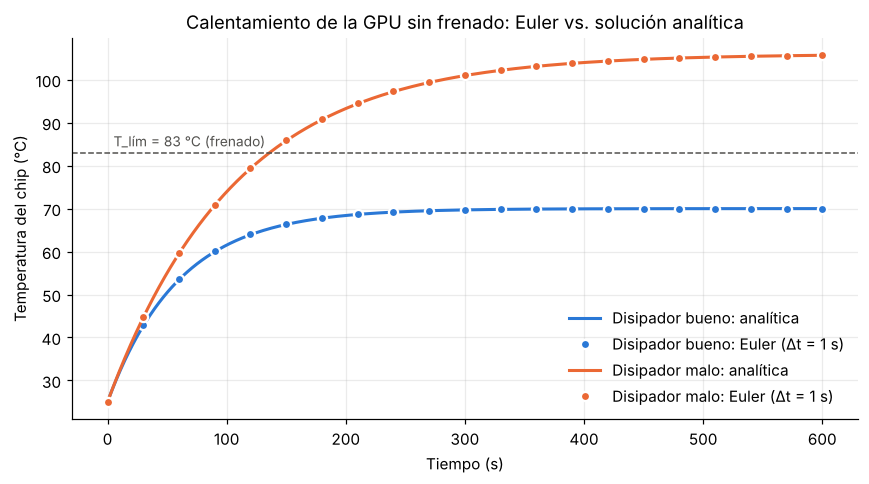

In [3]:
dt = 1.0          # s
t_final = 600.0   # s (10 minutos)
t_fino = np.linspace(0, t_final, 1000)

fig, ax = plt.subplots()
for R, color, nombre in [(R_BUENO, AZUL, "Disipador bueno"), (R_MALO, NARANJA, "Disipador malo")]:
    t, T = euler(F_sin_frenado(R), T_AMB, dt, t_final)
    ax.plot(t_fino, T_analitica(t_fino, R), color=color, lw=2, label=f"{nombre}: analítica")
    ax.plot(t[::30], T[::30], "o", color=color, ms=6, mec="white", mew=1.5,
            label=f"{nombre}: Euler (Δt = {dt:g} s)")
    err = np.max(np.abs(T - T_analitica(t, R)))
    print(f"{nombre}: error máximo de Euler = {err:.3f} °C")

ax.axhline(T_LIM, color=GRIS, ls="--", lw=1)
ax.text(5, T_LIM + 1.5, f"T_lím = {T_LIM:g} °C (frenado)", color=GRIS, fontsize=9)
ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Temperatura del chip (°C)")
ax.set_title("Calentamiento de la GPU sin frenado: Euler vs. solución analítica")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig("figuras/validacion_analitica.png", dpi=200)
plt.show()

**Interpretación.** Euler sigue la solución analítica con un error máximo menor a medio grado. Las dos curvas tienen la forma de la carga de un condensador: suben rápido al principio y se aplanan cerca de $T_{amb} + P R_{th}$. El disipador malo no solo llega más alto, también tarda más en estabilizarse porque su $\tau$ es mayor. Además, cruza la línea de 83 °C a los pocos minutos: en la realidad, en ese momento el chip empezaría a frenar, que es lo que modela la sección 9.

## 6. Validación 2: ¿cómo cambia el error con $\Delta t$?

Si Euler es de primer orden, al dividir $\Delta t$ entre 10 el error también debe dividirse aproximadamente entre 10. En una gráfica log-log eso es una recta de **pendiente 1**.

Pendiente del ajuste log-log: 1.029  (se espera ≈ 1 para Euler)


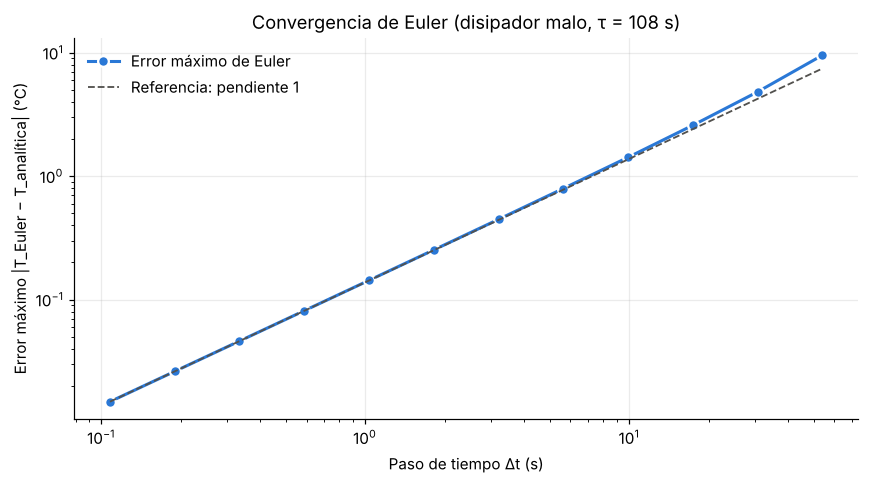

In [4]:
R = R_MALO
tau = R * C_TH
t_final = 5 * tau
pasos = tau * np.logspace(-3, np.log10(0.5), 12)   # desde tau/1000 hasta tau/2

errores = []
for h in pasos:
    t, T = euler(F_sin_frenado(R), T_AMB, h, t_final)
    errores.append(np.max(np.abs(T - T_analitica(t, R))))
errores = np.array(errores)

pendiente, _ = np.polyfit(np.log10(pasos), np.log10(errores), 1)
print(f"Pendiente del ajuste log-log: {pendiente:.3f}  (se espera ≈ 1 para Euler)")

fig, ax = plt.subplots()
ax.loglog(pasos, errores, "o-", color=AZUL, ms=7, mec="white", mew=1.5, label="Error máximo de Euler")
ax.loglog(pasos, errores[0] * (pasos / pasos[0]), "--", color=GRIS, lw=1.2, label="Referencia: pendiente 1")
ax.set_xlabel("Paso de tiempo Δt (s)")
ax.set_ylabel("Error máximo |T_Euler − T_analítica| (°C)")
ax.set_title(f"Convergencia de Euler (disipador malo, τ = {tau:.0f} s)")
ax.legend()
fig.tight_layout()
fig.savefig("figuras/convergencia_euler.png", dpi=200)
plt.show()

**Interpretación.** La pendiente sale muy cerca de 1, que confirma que nuestra implementación se comporta como un método de primer orden: el error es proporcional a $\Delta t$. En la práctica, esto nos da la regla para elegir el paso: si queremos que el error sea menor a una décima de grado, basta leer en la gráfica qué $\Delta t$ lo garantiza.

## 7. Estabilidad de Euler: ¿qué pasa si el paso es muy grande?

Llamemos $u = T - T_{eq}$ a la distancia al equilibrio. Al sustituir en Euler, cada paso multiplica esa distancia por un factor fijo:

$$
u_{k+1} = \left(1 - \frac{\Delta t}{\tau}\right) u_k .
$$

- Si $0 < \Delta t < \tau$: el factor está entre 0 y 1, y la solución se acerca al equilibrio sin oscilar (correcto).
- Si $\tau < \Delta t < 2\tau$: el factor es negativo, y la solución **oscila** alrededor del equilibrio aunque la física real no oscila.
- Si $\Delta t > 2\tau$: el factor tiene valor absoluto mayor que 1, y la solución **diverge**.

Este es exactamente el tipo de pregunta de la sustentación: "¿qué pasa si duplican el paso de tiempo?".

Δt = 0.5τ -> factor por paso 1 - Δt/τ = +0.50
Δt = 1.5τ -> factor por paso 1 - Δt/τ = -0.50
Δt = 2.2τ -> factor por paso 1 - Δt/τ = -1.20


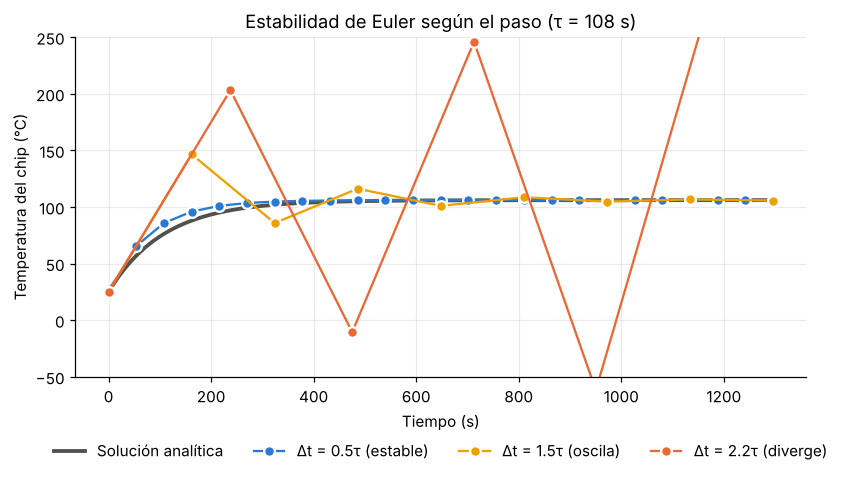

In [5]:
R = R_MALO
tau = R * C_TH
t_final = 12 * tau
t_fino = np.linspace(0, t_final, 1000)

fig, ax = plt.subplots()
ax.plot(t_fino, T_analitica(t_fino, R), color=GRIS, lw=2.5, label="Solución analítica")
casos = [(0.5, AZUL, "estable"), (1.5, AMARILLO, "oscila"), (2.2, NARANJA, "diverge")]
for factor, color, nombre in casos:
    t, T = euler(F_sin_frenado(R), T_AMB, factor * tau, t_final)
    ax.plot(t, T, "o-", color=color, ms=7, lw=1.5, mec="white", mew=1.5,
            label=f"Δt = {factor:g}τ ({nombre})")
    print(f"Δt = {factor:g}τ -> factor por paso 1 - Δt/τ = {1 - factor:+.2f}")

ax.set_ylim(-50, 250)
ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Temperatura del chip (°C)")
ax.set_title(f"Estabilidad de Euler según el paso (τ = {tau:.0f} s)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4)
fig.tight_layout()
fig.savefig("figuras/estabilidad_euler.png", dpi=200)
plt.show()

**Interpretación.** Con $\Delta t = 0.5\tau$ la simulación es tosca pero correcta. Con $\Delta t = 1.5\tau$ aparecen oscilaciones que no son físicas: el chip no "rebota" de temperatura en la realidad, es un artefacto del método. Con $\Delta t = 2.2\tau$ la temperatura crece sin límite. Conclusión práctica: en todas las simulaciones usaremos $\Delta t \ll \tau$. Esto será todavía más importante con el frenado, porque la regla de control también puede producir oscilaciones numéricas.

---
## 8. Medición propia

Para tener datos reales pusimos a trabajar los procesadores de nuestros portátiles con `medicion/benchmark.py`: todos los núcleos calculan hashes SHA-256 durante 15 minutos y luego el equipo queda 5 minutos en reposo. El script registra los hashes por segundo; al mismo tiempo, el programa **HWiNFO64** registra la temperatura del procesador, su potencia eléctrica y su frecuencia de reloj efectiva. Los dos archivos se unen por la hora del computador.

**Equipo 1:** ASUS TUF Gaming F15 (Intel Core de 4 núcleos y 8 hilos), conectado a la corriente. El portátil tiene tres modos (**Silencio**, **Rendimiento** y **Turbo**) que cambian el tope de potencia y la curva del ventilador. Primero analizamos en detalle el modo Silencio y luego comparamos los tres (sección 8.5).

### 8.1 Lectura de los datos

In [6]:
import csv
from datetime import datetime
from scipy.optimize import curve_fit

DATOS = "medicion/datos/"

def leer_benchmark(ruta):
    # CSV de benchmark.py: hora, t_s, fase, hashes_total, hashes_por_s, ...
    with open(ruta, encoding="utf-8") as f:
        filas = list(csv.DictReader(f))
    return {
        "inicio": datetime.fromisoformat(filas[0]["hora"]),
        "t": np.array([float(r["t_s"]) for r in filas]),
        "tasa": np.array([float(r["hashes_por_s"]) for r in filas]),
        "carga": np.array([r["fase"] == "carga" for r in filas]),
    }

def _hora_hwinfo(fecha, hora):
    # HWiNFO escribe la fecha como 15.11.2026 y la hora como 18:2:44.196
    d, m, a = fecha.split(".")
    h, mi, s = hora.split(":")
    seg, _, ms = s.partition(".")
    return datetime(int(a), int(m), int(d), int(h), int(mi), int(seg), int(ms.ljust(6, "0")[:6]))

# Nombres de columna posibles (HWiNFO en español o inglés, Intel o AMD)
COLUMNAS_HWINFO = {
    "T": ["CPU Entera [°C]", "CPU Package [°C]", "CPU (Tctl/Tdie) [°C]"],
    "P": ["Potencia total de CPU [W]", "CPU Package Power [W]"],
    "f": ["Relojes efectivos núcleo (avg) [MHz]", "Core Effective Clocks (avg) [MHz]"],
    "V": ["Core VIDs (avg) [V]", "VID núcleo (avg) [V]", "CPU Core Voltage (SVI2 TFN) [V]"],
    "ventilador": ["CPU [RPM]"],
    "freno_termico": ["Desaceleración térmica del núcleo (avg) [Yes/No]", "Core Thermal Throttling (avg) [Yes/No]"],
}

def _numero(texto):
    # HWiNFO escribe números o Sí/No
    if texto in ("Sí", "Si", "Yes"): return 1.0
    if texto == "No": return 0.0
    return float(texto)

def leer_hwinfo(ruta, inicio):
    # Devuelve el tiempo en segundos medido desde el inicio del benchmark
    with open(ruta, encoding="utf-8-sig", errors="replace") as f:
        filas = list(csv.reader(f))
    encabezado = filas[0]
    datos = [r for r in filas[1:] if r and r[0][:1].isdigit()]   # descarta filas de resumen
    salida = {"t": np.array([(_hora_hwinfo(r[0], r[1]) - inicio).total_seconds() for r in datos])}
    for clave, nombres in COLUMNAS_HWINFO.items():
        i = next((encabezado.index(n) for n in nombres if n in encabezado), None)
        salida[clave] = np.array([_numero(r[i]) for r in datos]) if i is not None else None
    return salida

bm = leer_benchmark(DATOS + "felipe_silencio_benchmark.csv")
hw = leer_hwinfo(DATOS + "felipe_silencio_hwinfo.csv", bm["inicio"])
t_fin_carga = bm["t"][bm["carga"]].max()
print(f"Benchmark: {len(bm['t'])} registros | HWiNFO: {len(hw['t'])} registros")
print(f"Fin de la carga: t = {t_fin_carga:.0f} s")

Benchmark: 1181 registros | HWiNFO: 604 registros
Fin de la carga: t = 901 s


### 8.2 Lo que pasó durante la medición

Graficamos temperatura, potencia y velocidad en tres paneles con el mismo eje de tiempo. La zona gris es el enfriamiento.

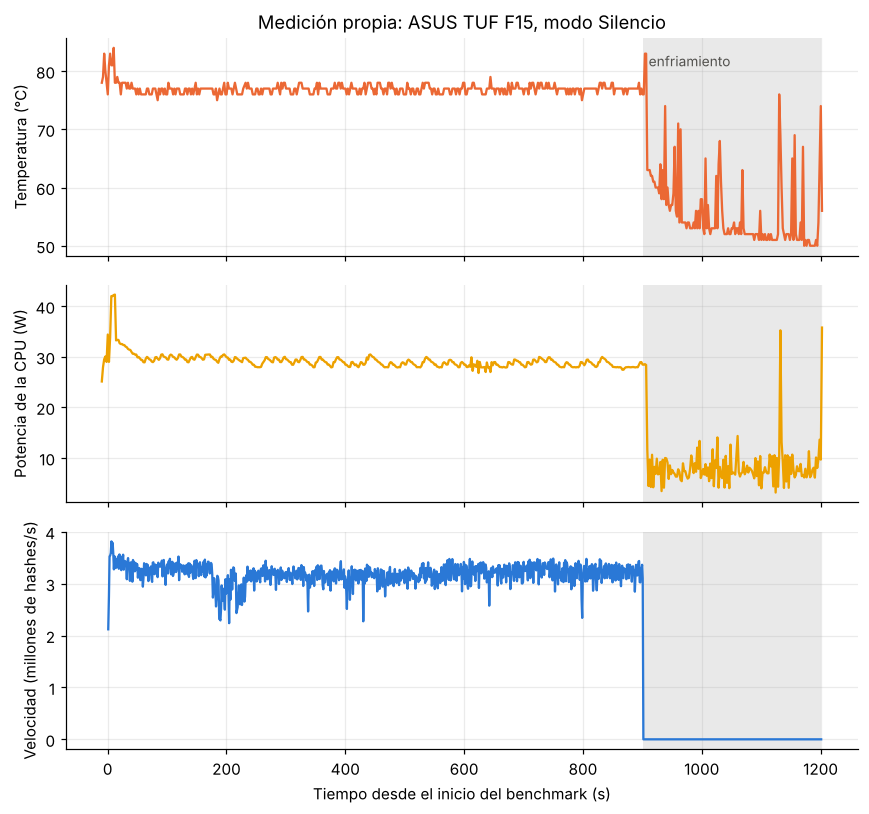

Primeros 10 s de carga: P máx = 42 W
Carga estable: T = 76.9 °C | P = 28.9 W | f efectiva = 2932 MHz
Reposo final:  T = 51.0 °C | P = 7.7 W


In [7]:
fig, ejes = plt.subplots(3, 1, figsize=(8, 7.5), sharex=True)
paneles = [
    (hw["t"], hw["T"], "Temperatura (°C)", NARANJA),
    (hw["t"], hw["P"], "Potencia de la CPU (W)", AMARILLO),
    (bm["t"][1:], bm["tasa"][1:] / 1e6, "Velocidad (millones de hashes/s)", AZUL),
]
for ax, (t, y, etiqueta, color) in zip(ejes, paneles):
    ax.axvspan(t_fin_carga, bm["t"].max(), color=GRIS, alpha=0.12, lw=0)
    ax.plot(t, y, color=color, lw=1.5)
    ax.set_ylabel(etiqueta)
ejes[0].text(t_fin_carga + 10, ejes[0].get_ylim()[1] * 0.97, "enfriamiento", color=GRIS, va="top", fontsize=9)
ejes[-1].set_xlabel("Tiempo desde el inicio del benchmark (s)")
ejes[0].set_title("Medición propia: ASUS TUF F15, modo Silencio")
fig.tight_layout()
fig.savefig("figuras/medicion_silencio.png", dpi=200)
plt.show()

carga = (hw["t"] > 60) & (hw["t"] < t_fin_carga)
reposo = hw["t"] > bm["t"].max() - 100
print("Primeros 10 s de carga: P máx = %.0f W" % hw["P"][(hw["t"] > 0) & (hw["t"] < 12)].max())
print("Carga estable: T = %.1f °C | P = %.1f W | f efectiva = %.0f MHz"
      % (hw["T"][carga].mean(), hw["P"][carga].mean(), hw["f"][carga].mean()))
print("Reposo final:  T = %.1f °C | P = %.1f W" % (np.median(hw["T"][reposo]), np.median(hw["P"][reposo])))

**Interpretación.** Se ven tres cosas importantes:

1. **El frenado en este modo es por potencia, no por temperatura.** Al arrancar, el procesador sube a unos 42 W durante unos 10 s (límite de corto plazo, *PL2*) y luego baja a unos 29 W (límite sostenido, *PL1*). HWiNFO marca "límite de potencia excedido: Sí" y "desaceleración térmica: No". El modo Silencio fija un tope de potencia bajo para que el ventilador no tenga que girar rápido. Al bajar la potencia, baja la frecuencia y con ella la velocidad de hashes (unos 5 % menos que en el primer minuto).
2. **La temperatura se estabiliza en unos 77 °C**, por debajo del límite térmico del chip, que es justo lo que predice el balance de energía: con potencia constante, $T$ tiende a $T_{amb} + P R_{th}$.
3. **El equipo ya estaba caliente al empezar** (unos 76 °C, con otros programas usando la CPU), así que esta medición no muestra la curva de calentamiento. Por eso usamos la de **enfriamiento**.

### 8.3 Ajuste de la curva de enfriamiento: medir $\tau$

Al quitar la carga, la potencia cae casi a cero y el balance de energía predice un decaimiento exponencial (ley de enfriamiento de Newton):

$$
T(t) = T_\infty + A\,e^{-t/\tau}.
$$

Empezamos el ajuste en la primera muestra en que la potencia ya cayó (menos de 15 W) y ajustamos $T_\infty$, $A$ y $\tau$ por mínimos cuadrados. Antes, quitamos los picos breves que producen otros programas del sistema operativo tomando el mínimo de cada 3 muestras vecinas.

tau medido = 44 ± 4 s | T_inf = 51.4 °C


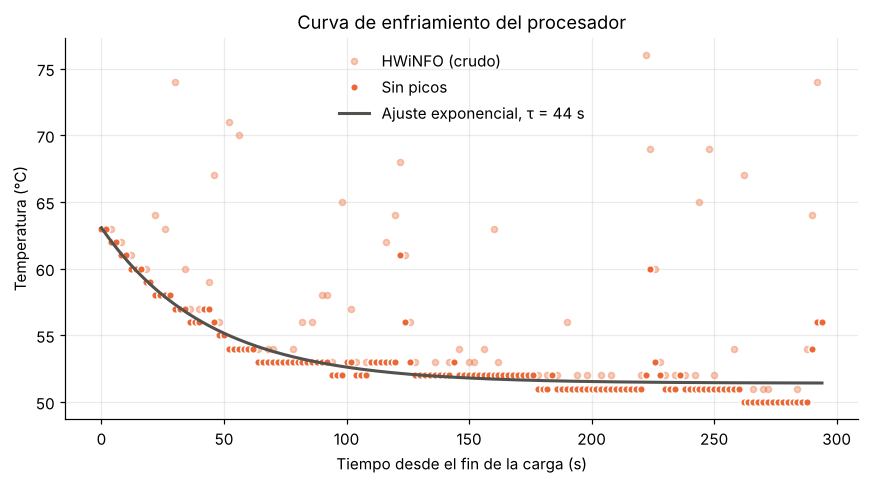

R_th efectiva = (76.9 − 51.0) °C / (28.9 − 7.7) W = 1.22 K/W
C_th efectiva = tau / R_th = 36 J/K


In [8]:
i0 = np.argmax((hw["t"] > t_fin_carga) & (hw["P"] < 15))   # primera muestra ya sin carga
m = np.arange(len(hw["t"])) >= i0
t_enf = hw["t"][m] - hw["t"][m][0]
T_enf = hw["T"][m]
T_suave = np.array([T_enf[max(0, i - 1):i + 2].min() for i in range(len(T_enf))])

def enfriamiento(t, T_inf, A, tau):
    return T_inf + A * np.exp(-t / tau)

(T_inf, A, tau_med), cov = curve_fit(enfriamiento, t_enf, T_suave, p0=[50, 10, 30])
err_tau = np.sqrt(cov[2, 2])
print(f"tau medido = {tau_med:.0f} ± {err_tau:.0f} s | T_inf = {T_inf:.1f} °C")

fig, ax = plt.subplots()
ax.plot(t_enf, T_enf, "o", color=NARANJA, ms=4, alpha=0.35, label="HWiNFO (crudo)")
ax.plot(t_enf, T_suave, "o", color=NARANJA, ms=5, mec="white", mew=1, label="Sin picos")
t_fino = np.linspace(0, t_enf.max(), 400)
ax.plot(t_fino, enfriamiento(t_fino, T_inf, A, tau_med), color=GRIS, lw=2,
        label=f"Ajuste exponencial, τ = {tau_med:.0f} s")
ax.set_xlabel("Tiempo desde el fin de la carga (s)")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Curva de enfriamiento del procesador")
ax.legend()
fig.tight_layout()
fig.savefig("figuras/enfriamiento_silencio.png", dpi=200)
plt.show()

# Resistencia térmica efectiva a partir de los dos estados estables (carga y reposo)
T_c, P_c = hw["T"][carga].mean(), hw["P"][carga].mean()
T_r, P_r = np.median(hw["T"][reposo]), np.median(hw["P"][reposo])
R_med = (T_c - T_r) / (P_c - P_r)
C_med = tau_med / R_med
print(f"R_th efectiva = ({T_c:.1f} − {T_r:.1f}) °C / ({P_c:.1f} − {P_r:.1f}) W = {R_med:.2f} K/W")
print(f"C_th efectiva = tau / R_th = {C_med:.0f} J/K")

**Interpretación.** Apenas se quita la carga, la temperatura cae unos 14 °C en menos de 2 s (antes de que empiece el ajuste): es el propio chip de silicio, que tiene muy poca masa y se enfría casi al instante. Después viene la parte lenta, que es el disipador y los tubos de calor, y que sí sigue muy bien una exponencial con $\tau \approx 44 \pm 4$ s.

Con la resistencia térmica efectiva (unos 1.2 K/W) obtenemos $C_{th} = \tau/R_{th} \approx 36$ J/K, que equivale a unos 90 g de cobre ($c = 385$ J/(kg·K)): razonable para el sistema de refrigeración de un portátil, y mucho menor que el de una tarjeta de escritorio como la RTX 4090.

Esta medición también muestra **límites de nuestro modelo de un solo nodo**: el chip y el disipador se comportan como dos cuerpos con tiempos distintos, y el ventilador cambia de velocidad en el reposo (de 3400 a 2400 rpm), lo que cambia $R_{th}$. Lo discutimos en la sección de limitaciones.

### 8.4 Energía por intento en nuestro portátil

In [9]:
r_c = bm["tasa"][bm["carga"] & (bm["t"] > 60)].mean()
E_hash = P_c / r_c
combinaciones = 95**8
t_8 = combinaciones / r_c
E_8 = combinaciones * E_hash
print(f"Velocidad estable: {r_c:.2e} hashes/s | Potencia: {P_c:.1f} W")
print(f"Energía por hash: {E_hash * 1e6:.1f} µJ  (RTX 4090 con NTLM: {P_MAX / 3e11 * 1e9:.1f} nJ)")
print(f"Contraseña de 8 caracteres en este portátil: {t_8 / 3.156e7:.0f} años y {E_8 / 3.6e6:,.0f} kWh (solo la CPU)")

Velocidad estable: 3.18e+06 hashes/s | Potencia: 28.9 W
Energía por hash: 9.1 µJ  (RTX 4090 con NTLM: 1.5 nJ)
Contraseña de 8 caracteres en este portátil: 66 años y 16,732 kWh (solo la CPU)


**Interpretación.** El portátil gasta unos 9 µJ por hash. Romper una contraseña de 8 caracteres le tomaría unos 66 años y unos 17 000 kWh solo en la CPU, lo que consume un hogar colombiano promedio en casi una década. Una GPU como la RTX 4090 hace el mismo trabajo en horas: es unas $10^5$ veces más rápida y, además, gasta unas 6000 veces menos energía por intento (1.5 nJ). Por eso los ataques reales se hacen con GPU. La comparación es aproximada: el hash de la GPU (NTLM) es más simple que SHA-256 y nuestro código está en Python.

### 8.5 Comparación de los tres modos

Repetimos la misma medición (15 min de carga y 5 min de reposo) en los modos Rendimiento y Turbo. Para cada modo calculamos los valores promedio en la carga estable (de $t = 60$ s al final de la carga).

In [10]:
MODOS = ["silencio", "rendimiento", "turbo"]
COLOR_MODO = {"silencio": AZUL, "rendimiento": AGUA, "turbo": NARANJA}

def resumen(quien, modo):
    # Promedios de la carga estable, R_th efectiva y tau del enfriamiento para una medición
    b = leer_benchmark(DATOS + f"{quien}_{modo}_benchmark.csv")
    h = leer_hwinfo(DATOS + f"{quien}_{modo}_hwinfo.csv", b["inicio"])
    fin = b["t"][b["carga"]].max()
    c = (h["t"] > 60) & (h["t"] < fin)
    rep = h["t"] > b["t"].max() - 100
    r = b["tasa"][b["carga"] & (b["t"] > 60)].mean()
    P, T = h["P"][c].mean(), h["T"][c].mean()
    # curva de enfriamiento, igual que en 8.3
    i0 = np.argmax((h["t"] > fin) & (h["P"] < 15))
    t_e, T_e = h["t"][i0:] - h["t"][i0], h["T"][i0:]
    T_e = np.array([T_e[max(0, i - 1):i + 2].min() for i in range(len(T_e))])
    (_, _, tau), cov = curve_fit(enfriamiento, t_e, T_e, p0=[50, 10, 30])
    return {
        "r": r, "P": P, "T": T, "f": h["f"][c].mean(), "V": h["V"][c].mean(),
        "ventilador": h["ventilador"][c].mean(), "E_hash": P / r,
        "R_th": (T - np.median(h["T"][rep])) / (P - np.median(h["P"][rep])),
        "tau": tau, "err_tau": np.sqrt(cov[2, 2]),
        "muestras": (h["P"][c], h["V"][c], h["f"][c]),
        "hw": h,
    }


resultados = {modo: resumen("felipe", modo) for modo in MODOS}

print(f"{'Modo':12s}{'hash/s':>10s}{'P (W)':>8s}{'f (MHz)':>9s}{'V (V)':>8s}{'T (°C)':>8s}{'vent. (rpm)':>12s}{'µJ/hash':>9s}{'R_th (K/W)':>11s}")
for modo, x in resultados.items():
    print(f"{modo:12s}{x['r']:10.2e}{x['P']:8.1f}{x['f']:9.0f}{x['V']:8.3f}{x['T']:8.1f}"
          f"{x['ventilador']:12.0f}{x['E_hash'] * 1e6:9.2f}{x['R_th']:11.2f}")

base = resultados["silencio"]
for modo in ["rendimiento", "turbo"]:
    x = resultados[modo]
    print(f"{modo} vs. silencio: velocidad {100 * (x['r'] / base['r'] - 1):+.0f} % | "
          f"potencia {100 * (x['P'] / base['P'] - 1):+.0f} % | energía por hash {100 * (x['E_hash'] / base['E_hash'] - 1):+.0f} %")

Modo            hash/s   P (W)  f (MHz)   V (V)  T (°C) vent. (rpm)  µJ/hash R_th (K/W)
silencio      3.18e+06    28.9     2932   0.904    76.9        3400     9.08       1.22
rendimiento   3.57e+06    37.1     3295   0.972    77.4        4901    10.39       0.99
turbo         3.89e+06    45.9     3570   1.032    81.3        5650    11.82       0.92
rendimiento vs. silencio: velocidad +12 % | potencia +28 % | energía por hash +14 %
turbo vs. silencio: velocidad +22 % | potencia +59 % | energía por hash +30 %


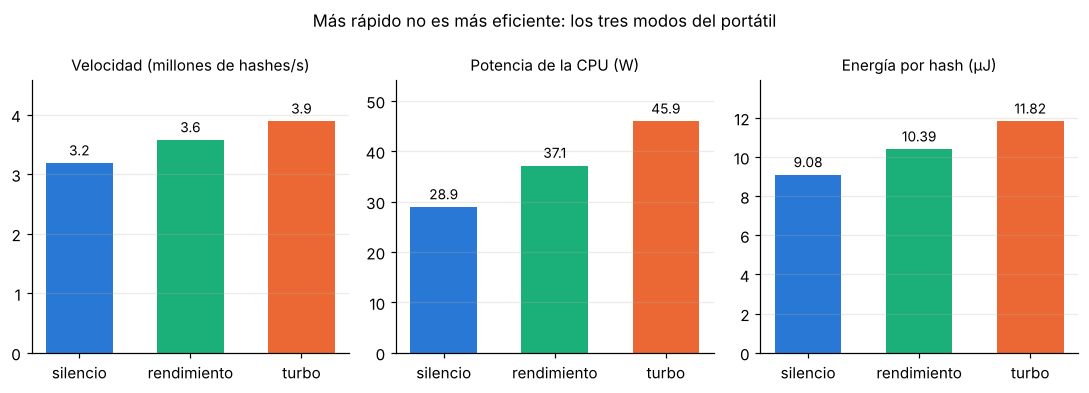

In [11]:
fig, ejes = plt.subplots(1, 3, figsize=(10, 3.6))
datos_barras = [
    ("r", 1e-6, "Velocidad (millones de hashes/s)"),
    ("P", 1, "Potencia de la CPU (W)"),
    ("E_hash", 1e6, "Energía por hash (µJ)"),
]
for ax, (clave, escala, titulo) in zip(ejes, datos_barras):
    valores = [resultados[m][clave] * escala for m in MODOS]
    barras = ax.bar(MODOS, valores, color=[COLOR_MODO[m] for m in MODOS], width=0.6)
    ax.bar_label(barras, fmt="%.1f" if clave != "E_hash" else "%.2f", padding=3, fontsize=9)
    ax.set_title(titulo, fontsize=10)
    ax.set_ylim(0, max(valores) * 1.18)
    ax.grid(axis="x", visible=False)
fig.suptitle("Más rápido no es más eficiente: los tres modos del portátil", fontsize=11)
fig.tight_layout()
fig.savefig("figuras/comparacion_modos.png", dpi=200)
plt.show()

**Interpretación.** Turbo prueba un 22 % más de contraseñas por segundo que Silencio, pero gasta un 59 % más de potencia, así que **cada intento cuesta un 30 % más de energía**. Era la predicción que hicimos a partir de $P \approx C V^2 f$: para subir la frecuencia el chip también tiene que subir el voltaje, y la potencia crece más rápido que la velocidad.

En los tres modos HWiNFO marca "límite de potencia excedido: Sí" y "desaceleración térmica: No": en este portátil el freno siempre es el **tope de potencia** que fija cada modo, y la temperatura (77 a 81 °C) es la consecuencia. El ventilador también cambia con el modo (de 3400 a 5650 rpm): más aire es más convección y por eso $R_{th}$ efectiva baja de 1.2 a 0.9 K/W.

### 8.6 Prueba directa del modelo de potencia: $P = C\,V^2 f$

HWiNFO también registra el voltaje de los núcleos. Si el modelo es correcto, al graficar $P$ contra $V^2 f$ todos los puntos, de los tres modos, deben caer sobre **una sola recta que pasa por el origen**, cuya pendiente es la capacitancia efectiva $C$ que el chip carga y descarga en cada ciclo.

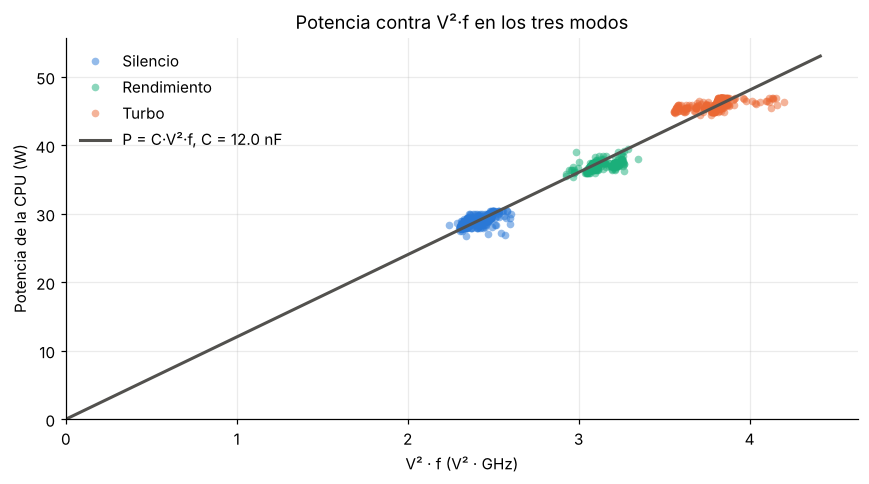

Capacitancia efectiva: C = 12.0 nF | R² = 0.986
  silencio     P/(V²f) = 12.06 nF
  rendimiento  P/(V²f) = 11.92 nF
  turbo        P/(V²f) = 12.09 nF


In [12]:
fig, ax = plt.subplots()
todos_x, todos_P = [], []
for modo in MODOS:
    P_m, V_m, f_m = resultados[modo]["muestras"]
    x = V_m**2 * f_m * 1e6          # V² · Hz
    ax.plot(x / 1e9, P_m, "o", color=COLOR_MODO[modo], ms=5, alpha=0.5, mec="none", label=modo.capitalize())
    todos_x.append(x); todos_P.append(P_m)
todos_x, todos_P = np.concatenate(todos_x), np.concatenate(todos_P)

C_ef = np.sum(todos_x * todos_P) / np.sum(todos_x**2)     # mínimos cuadrados, recta por el origen
residuo = todos_P - C_ef * todos_x
R2 = 1 - np.sum(residuo**2) / np.sum((todos_P - todos_P.mean())**2)
x_linea = np.linspace(0, todos_x.max() * 1.05, 50)
ax.plot(x_linea / 1e9, C_ef * x_linea, color=GRIS, lw=2, label=f"P = C·V²·f, C = {C_ef * 1e9:.1f} nF")
ax.set_xlim(left=0); ax.set_ylim(bottom=0)
ax.set_xlabel("V² · f (V² · GHz)")
ax.set_ylabel("Potencia de la CPU (W)")
ax.set_title("Potencia contra V²·f en los tres modos")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figuras/potencia_cv2f.png", dpi=200)
plt.show()

print(f"Capacitancia efectiva: C = {C_ef * 1e9:.1f} nF | R² = {R2:.3f}")
for modo in MODOS:
    P_m, V_m, f_m = resultados[modo]["muestras"]
    print(f"  {modo:12s} P/(V²f) = {np.mean(P_m / (V_m**2 * f_m * 1e6)) * 1e9:.2f} nF")

**Interpretación.** Entre los modos la potencia cambia un 59 %, pero el cociente $P/(V^2 f)$ es prácticamente el mismo en los tres (unos 12 nF). Es decir, el modelo $P = C V^2 f$ que usamos para la GPU **lo comprobamos con datos propios**. La $C$ que obtenemos no es la de un solo transistor: es la capacitancia total que el chip conmuta en cada ciclo de reloj (miles de millones de transistores multiplicados por la fracción que cambia de estado).

**Sobre $\tau$:** solo el modo Silencio da una curva de enfriamiento limpia. En Rendimiento y Turbo el ventilador baja de velocidad en escalones durante el reposo y el sistema operativo tuvo actividad de fondo (picos de hasta 46 W), así que $R_{th}$ cambia durante el enfriamiento y una sola exponencial no describe bien los datos. Por eso usamos $\tau \approx 44$ s del modo Silencio como valor medido.

### 8.7 Segundo equipo: el portátil de Alejandra

**Equipo 2:** ASUS VivoBook 15 (Intel de 4 núcleos y 8 hilos), un portátil delgado sin refrigeración "gamer", medido en los modos **Silencio** y **Rendimiento**. Esta vez HWiNFO registró una muestra por segundo, y en el modo Rendimiento el equipo empezó frío, así que también tenemos la curva de calentamiento.

In [13]:
resultados_ale = {modo: resumen("alejandra", modo) for modo in ["silencio", "rendimiento"]}
todas = [("Felipe", m, resultados[m]) for m in MODOS] + [("Alejandra", m, x) for m, x in resultados_ale.items()]

print(f"{'Equipo':10s}{'Modo':12s}{'hash/s':>9s}{'P (W)':>7s}{'V (V)':>7s}{'T (°C)':>7s}{'vent.':>7s}"
      f"{'µJ/hash':>9s}{'R_th':>6s}{'τ enfr. (s)':>13s}{'P/(V²f) (nF)':>14s}")
for quien, modo, x in todas:
    P_m, V_m, f_m = x["muestras"]
    C_m = np.mean(P_m / (V_m**2 * f_m * 1e6)) * 1e9
    print(f"{quien:10s}{modo:12s}{x['r']:9.2e}{x['P']:7.1f}{x['V']:7.3f}{x['T']:7.1f}{x['ventilador']:7.0f}"
          f"{x['E_hash'] * 1e6:9.2f}{x['R_th']:6.2f}{x['tau']:8.0f} ± {x['err_tau']:<3.0f}{C_m:12.2f}")

Equipo    Modo           hash/s  P (W)  V (V) T (°C)  vent.  µJ/hash  R_th  τ enfr. (s)  P/(V²f) (nF)
Felipe    silencio     3.18e+06   28.9  0.904   76.9   3400     9.08  1.22      44 ± 4         12.06
Felipe    rendimiento  3.57e+06   37.1  0.972   77.4   4901    10.39  0.99      27 ± 25        11.92
Felipe    turbo        3.89e+06   45.9  1.032   81.3   5650    11.82  0.92      77 ± 12        12.09
Alejandra silencio     3.60e+06   21.1  0.855   80.6   4479     5.87  2.17      40 ± 1          9.60
Alejandra rendimiento  3.55e+06   21.0  0.856   77.4   5388     5.91  2.01      33 ± 1          9.51


**Interpretación.**

- **Mismo trabajo, menos energía.** El portátil de Alejandra calcula unos 3.6 millones de hashes por segundo, casi lo mismo que el de Felipe, pero con solo 21 W: **unos 5.9 µJ por hash, un 35 % menos** que el modo más eficiente de Felipe. Su chip trabaja a menor voltaje (0.86 V contra 0.90 a 1.03 V) y conmuta menos capacitancia por ciclo.
- **La ley $P = C V^2 f$ se cumple también en otro chip.** En sus dos modos el cociente $P/(V^2 f)$ vuelve a ser constante, unos 9.5 nF: es la $C$ propia de su procesador, distinta de los 12 nF del de Felipe.
- **Disipador más pequeño, $R_{th}$ más grande.** Su resistencia térmica efectiva es de unos 2 K/W, casi el doble que la del portátil gamer. Por eso con apenas 21 W ya llega a unos 80 °C.
- **Un experimento controlado.** En este portátil los dos modos dan la misma potencia y la misma frecuencia (21 W y 3.0 GHz); lo único que cambia es el ventilador (unos 4500 contra 5400 rpm). Con la misma $P$, más aire significa menor $R_{th}$ y por eso la temperatura baja de 80.6 a 77.4 °C, tal como predice $T = T_{amb} + P R_{th}$. Los valores de $\tau$ de enfriamiento, ahora con datos cada segundo, salen con incertidumbre de ±1 s: 40 s en Silencio y 33 s en Rendimiento (con más ventilador, $R_{th}$ y $\tau = R_{th}C_{th}$ bajan).

Silencio: freno térmico activo entre t = 43 y 93 s, T máx = 92 °C
Rendimiento: τ de calentamiento = 9.5 ± 0.4 s | τ de enfriamiento = 33 s


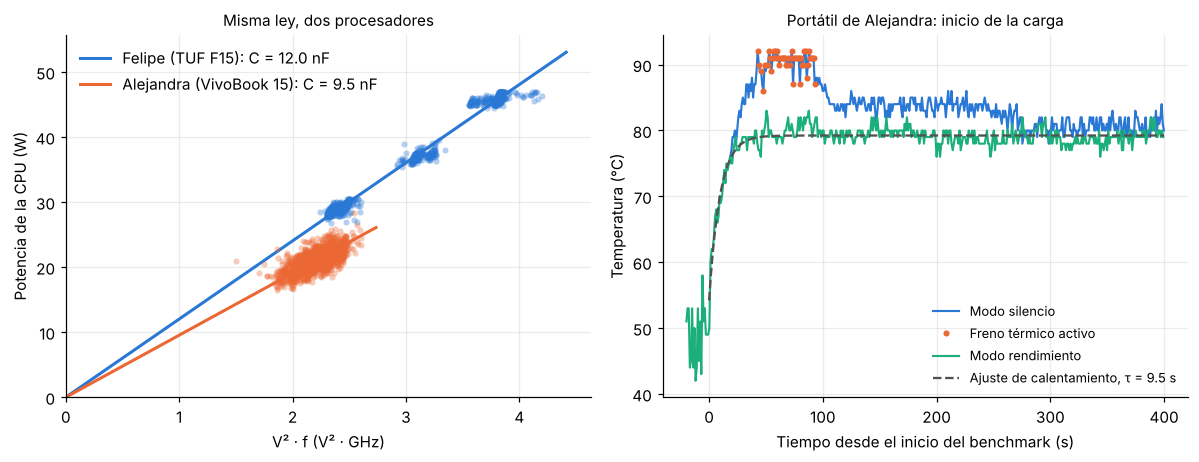

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.3))

# Izquierda: P contra V²f para los dos procesadores
for nombre, grupo, color in [("Felipe (TUF F15)", [resultados[m] for m in MODOS], AZUL),
                             ("Alejandra (VivoBook 15)", list(resultados_ale.values()), NARANJA)]:
    x = np.concatenate([g["muestras"][1]**2 * g["muestras"][2] * 1e6 for g in grupo])
    P_g = np.concatenate([g["muestras"][0] for g in grupo])
    C_g = np.sum(x * P_g) / np.sum(x**2)
    ax1.plot(x / 1e9, P_g, "o", color=color, ms=4, alpha=0.35, mec="none")
    x_l = np.linspace(0, x.max() * 1.05, 50)
    ax1.plot(x_l / 1e9, C_g * x_l, color=color, lw=2, label=f"{nombre}: C = {C_g * 1e9:.1f} nF")
ax1.set_xlim(left=0); ax1.set_ylim(bottom=0)
ax1.set_xlabel("V² · f (V² · GHz)")
ax1.set_ylabel("Potencia de la CPU (W)")
ax1.set_title("Misma ley, dos procesadores", fontsize=10)
ax1.legend(loc="upper left")

# Derecha: primeros 400 s de carga en los dos modos de Alejandra
def calentamiento(t, T_inf, A, tau):
    return T_inf - A * np.exp(-t / tau)

for modo, color in [("silencio", AZUL), ("rendimiento", AGUA)]:
    h = resultados_ale[modo]["hw"]
    m = (h["t"] >= -20) & (h["t"] <= 400)
    ax2.plot(h["t"][m], h["T"][m], color=color, lw=1.4, label=f"Modo {modo}")
    if modo == "silencio":
        frena = m & (h["freno_termico"] == 1)
        ax2.plot(h["t"][frena], h["T"][frena], "o", color=NARANJA, ms=4, mec="none",
                 label="Freno térmico activo")
        print(f"Silencio: freno térmico activo entre t = {h['t'][frena].min():.0f} y {h['t'][frena].max():.0f} s, "
              f"T máx = {h['T'][m].max():.0f} °C")
    else:
        mc = (h["t"] >= 0) & (h["t"] <= 400)
        (T_inf_c, A_c, tau_cal), cov_c = curve_fit(calentamiento, h["t"][mc], h["T"][mc], p0=[80, 30, 20])
        t_f = np.linspace(0, 400, 300)
        ax2.plot(t_f, calentamiento(t_f, T_inf_c, A_c, tau_cal), "--", color=GRIS, lw=1.5,
                 label=f"Ajuste de calentamiento, τ = {tau_cal:.1f} s")
        print(f"Rendimiento: τ de calentamiento = {tau_cal:.1f} ± {np.sqrt(cov_c[2, 2]):.1f} s | "
              f"τ de enfriamiento = {resultados_ale['rendimiento']['tau']:.0f} s")
ax2.set_xlabel("Tiempo desde el inicio del benchmark (s)")
ax2.set_ylabel("Temperatura (°C)")
ax2.set_title("Portátil de Alejandra: inicio de la carga", fontsize=10)
ax2.legend(loc="lower right", fontsize=8.5)
fig.tight_layout()
fig.savefig("figuras/segundo_equipo.png", dpi=200)
plt.show()

**Interpretación.**

- **Vimos el freno térmico en un chip real.** En modo Silencio el ventilador va más despacio y la temperatura sube hasta 92 °C; entre $t \approx 43$ s y $t \approx 93$ s HWiNFO marca "desaceleración térmica: Sí". Es el freno de la sección 9, pero aquí fue leve y corto: la frecuencia promedio bajó menos de un 1 % y la velocidad no cambió de forma medible. Luego el ventilador acelera y la temperatura se queda entre 77 y 86 °C.
- **Calentar y enfriar no tardan lo mismo.** El modelo de un solo cuerpo predice el mismo $\tau$ al calentar y al enfriar. Pero el ajuste da unos **10 s al calentar** y **33 s al enfriar**. La explicación es que hay al menos dos cuerpos: el chip de silicio, que tiene muy poca masa y se calienta en segundos (es la misma caída rápida que vimos en los primeros 2 s del enfriamiento de Felipe), y el disipador, que es más lento. Además, el ventilador cambia de velocidad durante la prueba, y con él $R_{th}$. Esta es la principal limitación de nuestro modelo térmico, y la discutimos en la sección 14.

**Pendiente:** la medición de Samuel.

---
## 9. Frenado: cómo se protege el chip

En la medición (sección 8) el procesador nunca dejó que su temperatura subiera sin control: cada modo le fija un **tope de potencia**, y además el chip tiene un **límite térmico** por si eso no alcanza. Una GPU tiene los mismos dos frenos. En esta sección los agregamos al modelo.

### 9.1 Potencia en función de la frecuencia

Usamos la frecuencia relativa $\varphi = f/f_{máx}$, de modo que $\varphi = 1$ es la velocidad máxima. La velocidad de intentos es $r = r_{máx}\,\varphi$ y la potencia es $P = C V^2 f$. Cuando un chip baja la frecuencia también baja el voltaje (lo vimos en la sección 8.5). Ajustamos una recta a los tres puntos $(f, V)$ que medimos y la normalizamos:

$$
\frac{V}{V_{máx}} = a + (1-a)\,\varphi
\qquad\Longrightarrow\qquad
P(\varphi) = P_{máx}\;\varphi\,\big(a + (1-a)\,\varphi\big)^2 .
$$

Como $r \propto \varphi$, la **energía por intento** es $P/r \propto \big(a + (1-a)\varphi\big)^2$: ir más despacio sale más barato por intento, igual que el modo Silencio en nuestro portátil.

**Suposición:** la GPU escala su voltaje igual que nuestro procesador. Solo lo medimos entre $\varphi \approx 0.8$ y $\varphi = 1$, que es justamente el rango en el que trabaja el frenado.

Recta medida: V = 0.320 V + 0.199 V/GHz · f
a = V(0) / V(f_máx) = 0.311


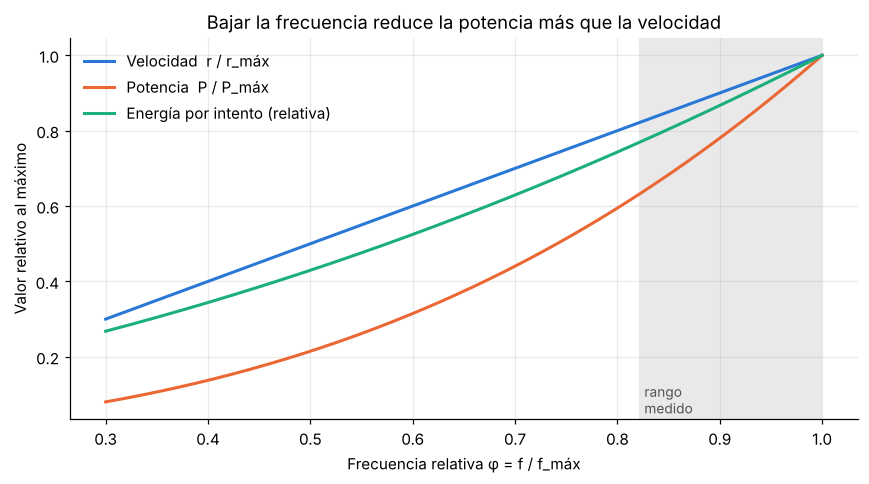

Con φ = 0.8: velocidad 80 %, potencia 59 %


In [15]:
f_modos = np.array([resultados[m]["f"] for m in MODOS])   # MHz
V_modos = np.array([resultados[m]["V"] for m in MODOS])   # V
pendiente_V, corte_V = np.polyfit(f_modos, V_modos, 1)
A_DVFS = corte_V / (pendiente_V * f_modos.max() + corte_V)
print(f"Recta medida: V = {corte_V:.3f} V + {pendiente_V * 1000:.3f} V/GHz · f")
print(f"a = V(0) / V(f_máx) = {A_DVFS:.3f}")


def potencia(phi):
    # Potencia eléctrica (W) con frecuencia relativa phi, incluyendo la bajada de voltaje
    return P_MAX * phi * (A_DVFS + (1 - A_DVFS) * phi)**2


def biseccion(g, izq, der, tol=1e-9):
    # Raíz de g en [izq, der] por bisección; g(izq) y g(der) deben tener signos opuestos
    g_izq = g(izq)
    while der - izq > tol:
        medio = (izq + der) / 2
        g_medio = g(medio)
        if (g_medio > 0) == (g_izq > 0):
            izq, g_izq = medio, g_medio
        else:
            der = medio
    return (izq + der) / 2


phi_graf = np.linspace(0.3, 1, 200)
fig, ax = plt.subplots()
ax.plot(phi_graf, phi_graf, color=AZUL, label="Velocidad  r / r_máx")
ax.plot(phi_graf, potencia(phi_graf) / P_MAX, color=NARANJA, label="Potencia  P / P_máx")
ax.plot(phi_graf, (A_DVFS + (1 - A_DVFS) * phi_graf)**2, color=AGUA, label="Energía por intento (relativa)")
ax.axvspan(f_modos.min() / f_modos.max(), 1, color=GRIS, alpha=0.12, lw=0)
ax.text(f_modos.min() / f_modos.max() + 0.005, 0.05, "rango\nmedido", color=GRIS, fontsize=9)
ax.set_xlabel("Frecuencia relativa φ = f / f_máx")
ax.set_ylabel("Valor relativo al máximo")
ax.set_title("Bajar la frecuencia reduce la potencia más que la velocidad")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig("figuras/potencia_vs_frecuencia.png", dpi=200)
plt.show()
print(f"Con φ = 0.8: velocidad 80 %, potencia {100 * potencia(0.8) / P_MAX:.0f} %")

### 9.2 Los dos frenos

- **Tope de potencia.** El chip no puede pasar de $P_{tope}$, así que $\varphi \le \varphi_P$, donde $P(\varphi_P) = P_{tope}$. Esa ecuación no tiene despeje sencillo, así que la resolvemos por bisección. Es lo que hacen los modos del portátil.
- **Límite térmico.** Probamos dos reglas:
  - *Proporcional:* por cada grado por encima de $T_{lím}$ la frecuencia baja una fracción $K$: $\;\varphi_T = 1 - K\,(T - T_{lím})$, limitada entre $\varphi_{mín}$ y 1.
  - *Encendido/apagado:* si $T > T_{lím}$, $\varphi_T = \varphi_{mín}$; si no, $\varphi_T = 1$.

El chip obedece al freno más estricto: $\varphi = \min(\varphi_P,\ \varphi_T(T))$. Así, la ecuación del chip sigue siendo una sola,

$$
C_{th}\frac{dT}{dt} = P\big(\varphi(T)\big) - \frac{T - T_{amb}}{R_{th}},
$$

pero ahora es **no lineal**, porque $\varphi$ depende de $T$. Ya no tiene solución analítica sencilla, y la resolvemos con el mismo `euler` de la sección 4.

In [16]:
PHI_MIN = 0.5    # frecuencia relativa mínima a la que puede bajar el chip
K_FRENO = 0.10   # 1/°C: la frecuencia baja 10 % por cada grado sobre T_LIM


def phi_por_tope(P_tope):
    # Frecuencia relativa máxima permitida por el tope de potencia
    if P_tope >= P_MAX:
        return 1.0
    return biseccion(lambda p: potencia(p) - P_tope, 0.0, 1.0)


def regla_frenado(P_tope=P_MAX, control="proporcional"):
    # Devuelve la función phi(T) con los dos frenos
    phi_P = phi_por_tope(P_tope)

    def phi(T):
        if control == "proporcional":
            phi_T = min(1.0, max(PHI_MIN, 1 - K_FRENO * (T - T_LIM)))
        elif control == "on/off":
            phi_T = PHI_MIN if T > T_LIM else 1.0
        else:                       # sin freno térmico
            phi_T = 1.0
        return min(phi_P, phi_T)

    return phi


def simular(R_th, P_tope=P_MAX, control="proporcional", dt=0.5, t_final=600):
    phi = regla_frenado(P_tope, control)
    F = lambda t, T: (potencia(phi(T)) - (T - T_AMB) / R_th) / C_TH
    t, T = euler(F, T_AMB, dt, t_final)
    return t, T, np.array([phi(x) for x in T])


ESCENARIOS = {
    "A: disipador bueno": dict(R_th=R_BUENO, P_tope=P_MAX),
    "B: disipador malo": dict(R_th=R_MALO, P_tope=P_MAX),
    "C: bueno con tope de 300 W": dict(R_th=R_BUENO, P_tope=300.0),
}
COLOR_ESC = dict(zip(ESCENARIOS, [AZUL, NARANJA, AGUA]))

### 9.3 Tres escenarios

- **A:** disipador bueno, sin tope de potencia.
- **B:** disipador malo (polvo, pasta térmica seca), sin tope de potencia.
- **C:** disipador bueno con un tope de 300 W, como un "modo silencio" de la GPU.

A: disipador bueno           al final: T =  70.0 °C | φ = 1.000 | P =   450 W
B: disipador malo            al final: T =  84.2 °C | φ = 0.875 | P =   329 W
C: bueno con tope de 300 W   al final: T =  55.0 °C | φ = 0.841 | P =   300 W


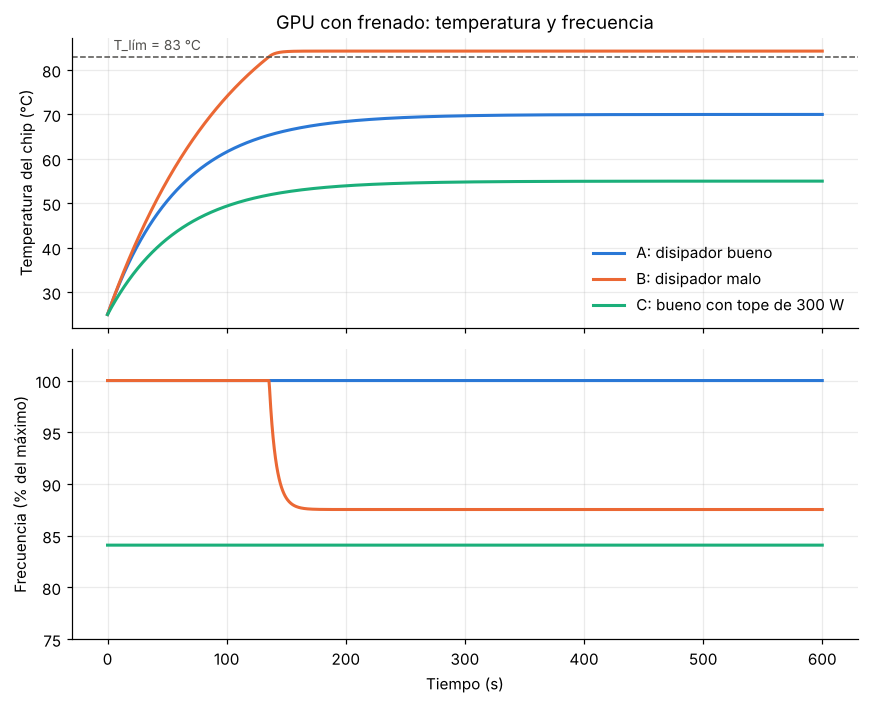

In [17]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6.5), sharex=True)
for nombre, esc in ESCENARIOS.items():
    t, T, phi = simular(**esc, dt=0.5, t_final=600)
    ax1.plot(t, T, color=COLOR_ESC[nombre], label=nombre)
    ax2.plot(t, 100 * phi, color=COLOR_ESC[nombre], label=nombre)
    print(f"{nombre:28s} al final: T = {T[-1]:5.1f} °C | φ = {phi[-1]:.3f} | P = {potencia(phi[-1]):5.0f} W")
ax1.axhline(T_LIM, color=GRIS, ls="--", lw=1)
ax1.text(5, T_LIM + 1.5, f"T_lím = {T_LIM:g} °C", color=GRIS, fontsize=9)
ax1.set_ylabel("Temperatura del chip (°C)")
ax1.set_title("GPU con frenado: temperatura y frecuencia")
ax1.legend(loc="lower right")
ax2.set_ylabel("Frecuencia (% del máximo)")
ax2.set_ylim(75, 103)
ax2.set_xlabel("Tiempo (s)")
fig.tight_layout()
fig.savefig("figuras/frenado_escenarios.png", dpi=200)
plt.show()

**Interpretación.**

- **A:** se estabiliza en 70 °C sin tocar el límite, así que trabaja al 100 % todo el tiempo.
- **B:** a los 2 minutos llega a 83 °C y el freno empieza a actuar. La temperatura se queda un poco por encima del límite y la frecuencia se estabiliza en un 88 %. El freno no apaga el calentamiento: busca la frecuencia exacta en la que el calor que entra iguala al que el disipador logra sacar.
- **C:** el tope de potencia baja la frecuencia desde el primer segundo (al 84 %). El chip queda frío (55 °C) porque nunca le llega a la temperatura límite: el freno es por potencia, que es lo mismo que medimos en el portátil.

### 9.4 Validación: el equilibrio calculado sin simular

En el equilibrio $dT/dt = 0$, así que la temperatura final debe cumplir

$$
G(T) = P\big(\varphi(T)\big) - \frac{T - T_{amb}}{R_{th}} = 0 .
$$

Resolvemos esa ecuación por bisección, **sin usar Euler**, y comparamos con el final de la simulación.

In [18]:
print(f"{'Escenario':28s}{'T simulada':>12s}{'T bisección':>13s}{'diferencia':>12s}")
for nombre, esc in ESCENARIOS.items():
    phi = regla_frenado(esc["P_tope"])
    G = lambda T: potencia(phi(T)) - (T - T_AMB) / esc["R_th"]
    T_eq = biseccion(G, T_AMB, 200.0)
    _, T_sim, _ = simular(**esc, dt=0.5, t_final=1500)
    print(f"{nombre:28s}{T_sim[-1]:12.3f}{T_eq:13.3f}{abs(T_sim[-1] - T_eq):12.1e}")

Escenario                     T simulada  T bisección  diferencia
A: disipador bueno                70.000       70.000     8.6e-10
B: disipador malo                 84.246       84.246     2.1e-10
C: bueno con tope de 300 W        55.000       55.000     4.9e-10


**Interpretación.** Los dos métodos coinciden con una diferencia de menos de una milmillonésima de grado. Es una validación independiente de la anterior: allá comparamos contra una fórmula; aquí, contra una ecuación algebraica resuelta con otro método numérico.

### 9.5 El frenado vuelve el sistema más rápido: cuidado con $\Delta t$

Con el freno proporcional, si la temperatura sube un grado sobre el equilibrio la frecuencia baja $K$, y la potencia baja $K\,P'(\varphi)$. Linealizando alrededor del equilibrio, la distancia $u = T - T_{eq}$ cumple

$$
C_{th}\frac{du}{dt} = -\left(\frac{1}{R_{th}} + K\,P'(\varphi_{eq})\right)u
\qquad\Longrightarrow\qquad
\tau_{ef} = \frac{C_{th}}{1/R_{th} + K\,P'(\varphi_{eq})} .
$$

El freno añade una "salida de calor" extra, así que el sistema reacciona mucho más rápido que $\tau = R_{th}C_{th}$. Por la sección 7, Euler oscila si $\Delta t > \tau_{ef}$ y se vuelve inestable si $\Delta t > 2\tau_{ef}$. Lo comprobamos con el escenario B y las dos reglas de freno.

τ sin freno = 108 s | τ efectivo con freno = 6.5 s
Euler oscila si Δt > 6.5 s y no converge si Δt > 12.9 s

on/off, Δt =  0.5 s: oscilación de 0.3 °C, φ promedio = 0.818
on/off, Δt =  8.0 s: oscilación de 4.5 °C, φ promedio = 0.816
proporcional:        φ en equilibrio = 0.875


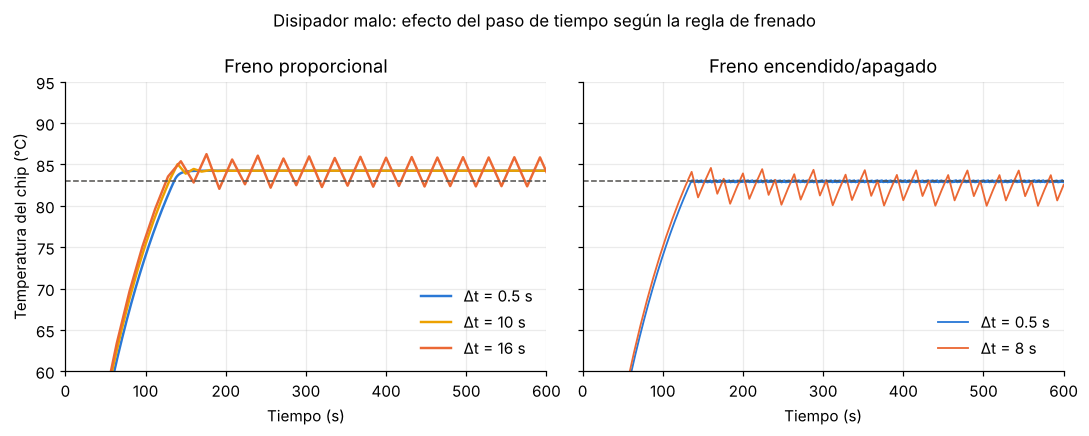

In [19]:
R = R_MALO
phi_B = regla_frenado()
T_eq_B = biseccion(lambda T: potencia(phi_B(T)) - (T - T_AMB) / R, T_AMB, 200.0)
phi_eq = phi_B(T_eq_B)
dP = (potencia(phi_eq + 1e-6) - potencia(phi_eq - 1e-6)) / 2e-6     # derivada numérica P'(φ)
tau_ef = C_TH / (1 / R + K_FRENO * dP)
print(f"τ sin freno = {R * C_TH:.0f} s | τ efectivo con freno = {tau_ef:.1f} s")
print(f"Euler oscila si Δt > {tau_ef:.1f} s y no converge si Δt > {2 * tau_ef:.1f} s\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for dt, color in [(0.5, AZUL), (10, AMARILLO), (16, NARANJA)]:
    t, T, _ = simular(R, control="proporcional", dt=dt, t_final=600)
    ax1.plot(t, T, "-", color=color, lw=1.6, label=f"Δt = {dt:g} s")
for dt, color in [(0.5, AZUL), (8, NARANJA)]:
    t, T, phi = simular(R, control="on/off", dt=dt, t_final=1200)
    ax2.plot(t[t <= 600], T[t <= 600], "-", color=color, lw=1.2, label=f"Δt = {dt:g} s")
    final = t > 900
    print(f"on/off, Δt = {dt:4.1f} s: oscilación de {T[final].max() - T[final].min():.1f} °C, "
          f"φ promedio = {phi[final].mean():.3f}")
_, _, phi_p = simular(R, dt=0.5, t_final=1200)
print(f"proporcional:        φ en equilibrio = {phi_p[-1]:.3f}")

for ax, titulo in [(ax1, "Freno proporcional"), (ax2, "Freno encendido/apagado")]:
    ax.axhline(T_LIM, color=GRIS, ls="--", lw=1)
    ax.set_title(titulo)
    ax.set_xlabel("Tiempo (s)")
    ax.set_xlim(0, 600)
    ax.set_ylim(60, 95)
    ax.legend(loc="lower right")
ax1.set_ylabel("Temperatura del chip (°C)")
fig.suptitle("Disipador malo: efecto del paso de tiempo según la regla de frenado", fontsize=11)
fig.tight_layout()
fig.savefig("figuras/frenado_estabilidad.png", dpi=200)
plt.show()

**Interpretación.**

- **Freno proporcional:** $\tau_{ef}$ es de unos 6.5 s, unas 16 veces menor que $\tau$. Con $\Delta t = 0.5$ s la curva es suave. Con $\Delta t = 10$ s (entre $\tau_{ef}$ y $2\tau_{ef}$) aparece una oscilación que se apaga. Con $\Delta t = 16$ s (más de $2\tau_{ef}$) la oscilación es permanente y solo la contienen los límites de $\varphi$. Ninguna de esas oscilaciones es física. Un paso de 10 s, que sin freno sería perfectamente seguro ($\tau = 108$ s), con freno ya produce oscilaciones.
- **Freno encendido/apagado:** la temperatura siempre "tiembla" alrededor de 83 °C, porque el chip alterna entre velocidad completa y media velocidad. La amplitud de ese temblor es proporcional a $\Delta t$ y por tanto es un artefacto numérico. En cambio, la frecuencia promedio (0.82) es menor que con el freno proporcional (0.88), y eso no depende de $\Delta t$: como $P(\varphi)$ es una curva cóncava hacia arriba, alternar entre dos extremos gasta más potencia que quedarse en el punto medio, y el chip tiene que ir más despacio en promedio para no calentarse.

**Decisión:** usamos el freno proporcional, con $\Delta t \le 0.5$ s, muy por debajo de $\tau_{ef}$.

---
## 10. El ataque: tiempo y energía

### 10.1 Tres ecuaciones acopladas

Ahora unimos el chip con el ataque. Además de la temperatura, llevamos la cuenta de los intentos $n$ y de la energía eléctrica $E$:

$$
\frac{dT}{dt} = \frac{1}{C_{th}}\left[P(\varphi) - \frac{T - T_{amb}}{R_{th}}\right],
\qquad
\frac{dn}{dt} = r_{máx}\,\varphi(T),
\qquad
\frac{dE}{dt} = P(\varphi(T)),
$$

desde $n = 0$ hasta $n = 95^N$. Las tres se integran con Euler en el mismo bucle. Así, la velocidad del ataque **sale de la dinámica térmica** y no de una división fija.

**Refrigeración.** Toda la energía eléctrica termina como calor $Q = E$ en el cuarto. Un aire acondicionado lo saca con un trabajo $W = Q/\mathrm{COP}$. El máximo teórico es el de Carnot, $\mathrm{COP}_{máx} = T_{frío}/(T_{caliente} - T_{frío})$; uno real ronda $\mathrm{COP} \approx 3$, que es el que usamos.

**Ataques de miles de años.** No podemos dar $10^{13}$ pasos de Euler. Pero después de unas pocas constantes de tiempo el chip ya está en equilibrio (tras $20\tau$, lo que falta del transitorio es $e^{-20} \approx 2\times10^{-9}$). Entonces simulamos paso a paso las primeras $20\tau$ y el resto lo completamos con la velocidad de equilibrio que dio la propia simulación. En 10.2 comprobamos que eso no cambia el resultado.

**Velocidades de la RTX 4090** (benchmarks públicos de hashcat, aproximados): NTLM, el hash de las contraseñas de Windows, unos $3\times10^{11}$ intentos/s; bcrypt, un hash diseñado para ser lento, unos $2\times10^{5}$ intentos/s.

In [20]:
ALFABETO = 95
VEL_HASH = {"NTLM": 3e11, "bcrypt": 2e5}    # intentos/s de una RTX 4090 a φ = 1
COP = 3.0                                   # aire acondicionado real
AÑO = 3.156e7                               # s
COP_carnot = (273.15 + 25) / (35 - 25)
print(f"COP de Carnot (cuarto a 25 °C, exterior a 35 °C) = {COP_carnot:.0f}; usamos COP real = {COP:g}")


def ataque(N, r_max, R_th, P_tope=P_MAX, control="proporcional", dt=0.1, n_tau=20):
    # Tiempo (s) y energía eléctrica (J) para probar las 95^N combinaciones
    total = float(ALFABETO)**N
    phi = regla_frenado(P_tope, control)
    t_sim = n_tau * R_th * C_TH
    t = n = E = 0.0
    T = T_AMB
    while t < t_sim:
        ph = phi(T)
        r, P = r_max * ph, potencia(ph)
        if n + dt * r >= total:                 # el ataque termina dentro de este paso
            fraccion = (total - n) / r
            return dict(t=t + fraccion, E=E + P * fraccion, phi=ph)
        T += dt * (P - (T - T_AMB) / R_th) / C_TH
        n += dt * r
        E += dt * P
        t += dt
    ph = phi(T)                                 # equilibrio: el resto a velocidad constante
    r, P = r_max * ph, potencia(ph)
    t_resto = (total - n) / r
    return dict(t=t + t_resto, E=E + P * t_resto, phi=ph)


def tiempo_legible(s):
    if s < 60: return f"{s:.1f} s"
    if s < 3600: return f"{s / 60:.1f} min"
    if s < 86400: return f"{s / 3600:.1f} h"
    if s < AÑO: return f"{s / 86400:.1f} días"
    if s < 1e4 * AÑO: return f"{s / AÑO:.0f} años"
    return f"{s / AÑO:.1e} años"

COP de Carnot (cuarto a 25 °C, exterior a 35 °C) = 30; usamos COP real = 3


### 10.2 Validación de la extrapolación

Una contraseña de 8 caracteres con NTLM tarda unas horas, así que sí podemos simularla completa paso a paso y compararla con la versión que extrapola después de $20\tau$.

In [21]:
for nombre, esc in ESCENARIOS.items():
    rapido = ataque(8, VEL_HASH["NTLM"], **esc, dt=0.5)
    completo = ataque(8, VEL_HASH["NTLM"], **esc, dt=0.5, n_tau=1e6)
    print(f"{nombre:28s} completo: {completo['t']:9.1f} s | extrapolado: {rapido['t']:9.1f} s | "
          f"diferencia relativa: {abs(rapido['t'] - completo['t']) / completo['t']:.1e}")

A: disipador bueno           completo:   22114.0 s | extrapolado:   22114.0 s | diferencia relativa: 0.0e+00
B: disipador malo            completo:   25242.7 s | extrapolado:   25242.7 s | diferencia relativa: 6.9e-13
C: bueno con tope de 300 W   completo:   26297.2 s | extrapolado:   26297.2 s | diferencia relativa: 4.3e-13


**Interpretación.** La diferencia es despreciable. Extrapolar con la velocidad de equilibrio da el mismo resultado que simular horas enteras, y nos deja calcular ataques de miles de años en milisegundos.

### 10.3 ¿Cuánto cuesta una contraseña de 8 caracteres?

In [22]:
print(f"{'Escenario':28s}{'Hash':>8s}{'Tiempo':>14s}{'φ':>7s}{'E eléctrica':>14s}{'+ aire acond.':>15s}{'J por intento':>15s}")
for nombre, esc in ESCENARIOS.items():
    for hash_, r_max in VEL_HASH.items():
        res = ataque(8, r_max, **esc)
        E_total = res["E"] * (1 + 1 / COP)
        print(f"{nombre:28s}{hash_:>8s}{tiempo_legible(res['t']):>14s}{res['phi']:7.3f}"
              f"{res['E'] / 3.6e6:11.3g} kWh{E_total / 3.6e6:11.3g} kWh{res['E'] / float(ALFABETO)**8:15.3g}")

Escenario                       Hash        Tiempo      φ   E eléctrica  + aire acond.  J por intento
A: disipador bueno              NTLM         6.1 h  1.000       2.76 kWh       3.69 kWh        1.5e-09
A: disipador bueno            bcrypt     1051 años  1.000   4.15e+06 kWh   5.53e+06 kWh        0.00225
B: disipador malo               NTLM         7.0 h  0.875       2.31 kWh       3.08 kWh       1.25e-09


B: disipador malo             bcrypt     1201 años  0.875   3.46e+06 kWh   4.62e+06 kWh        0.00188
C: bueno con tope de 300 W      NTLM         7.3 h  0.841       2.19 kWh       2.92 kWh       1.19e-09
C: bueno con tope de 300 W    bcrypt     1250 años  0.841   3.29e+06 kWh   4.38e+06 kWh        0.00178


**Interpretación.**

- **NTLM:** con la GPU en buen estado, 8 caracteres caen en unas **6 horas** y unos **3.7 kWh** contando el aire acondicionado: más o menos lo que gasta una nevera en unos pocos días. Una contraseña así no protege nada.
- **bcrypt:** el mismo ataque tarda **más de mil años** y millones de kWh. La física del chip es la misma; lo único que cambia es que bcrypt obliga a hacer muchísimo más trabajo por intento. Por eso los sistemas serios guardan las contraseñas con hashes lentos.
- **El disipador malo (B) y el tope de potencia (C)** hacen el ataque entre un 14 % y un 19 % más lento, pero gastan **menos** energía total, porque trabajan a menor voltaje. Es lo mismo que medimos en el portátil (Silencio contra Turbo): el frenado cambia tiempo por energía.

### 10.4 ¿Cuándo importa la dinámica térmica?

Para cada duración posible del ataque calculamos la **velocidad promedio** como fracción de $r_{máx}$. Si el modelo térmico no importara, sería 1 siempre.

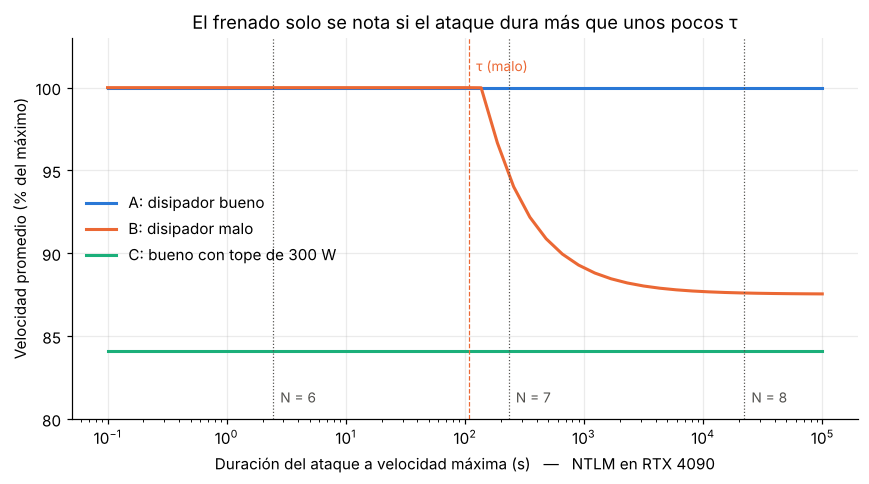

In [23]:
duraciones = np.logspace(-1, 5, 45)          # duración del ataque sin frenado, en s
fig, ax = plt.subplots()
for nombre, esc in ESCENARIOS.items():
    fraccion = []
    for d in duraciones:
        N_equiv = np.log(d * VEL_HASH["NTLM"]) / np.log(ALFABETO)   # N (no entero) con esa duración
        res = ataque(N_equiv, VEL_HASH["NTLM"], **esc, dt=0.2)
        fraccion.append(d / res["t"])
    ax.semilogx(duraciones, 100 * np.array(fraccion), color=COLOR_ESC[nombre], label=nombre)

for N in [6, 7, 8]:
    d = float(ALFABETO)**N / VEL_HASH["NTLM"]
    ax.axvline(d, color=GRIS, lw=0.8, ls=":")
    ax.text(d * 1.15, 81, f"N = {N}", color=GRIS, fontsize=9)
ax.axvline(R_MALO * C_TH, color=NARANJA, lw=0.8, ls="--")
ax.text(R_MALO * C_TH * 1.15, 101, "τ (malo)", color=NARANJA, fontsize=9)
ax.set_ylim(80, 103)
ax.set_xlabel("Duración del ataque a velocidad máxima (s)   —   NTLM en RTX 4090")
ax.set_ylabel("Velocidad promedio (% del máximo)")
ax.set_title("El frenado solo se nota si el ataque dura más que unos pocos τ")
ax.legend(loc="center left")
fig.tight_layout()
fig.savefig("figuras/velocidad_vs_duracion.png", dpi=200)
plt.show()

**Interpretación.** En el escenario B, un ataque de pocos segundos (6 caracteres) va al 100 %: el chip está frío y su capacidad térmica absorbe el calor antes de llegar al límite. Alrededor de $\tau$ la velocidad promedio empieza a caer, y para ataques largos se estabiliza en la velocidad de equilibrio. El tope de potencia (C), en cambio, actúa desde el primer segundo, sin importar la duración.

Esta gráfica es la respuesta a "¿para qué el modelo térmico, si basta dividir combinaciones entre velocidad?": la división funciona solo en los extremos, y cuál es la velocidad de equilibrio lo decide la física del disipador.

### 10.5 Tiempo y energía según la longitud de la contraseña

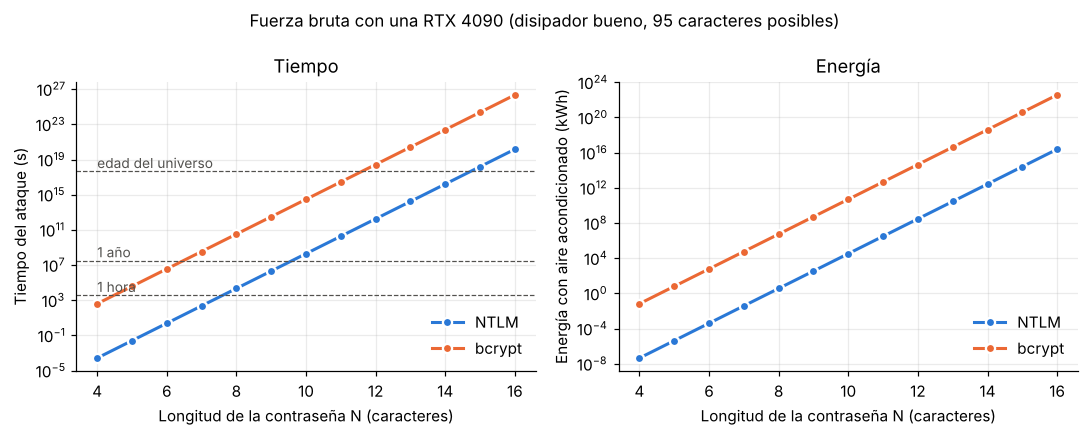

N =  8 (NTLM):            6.1 h | 3.69e+00 kWh
N = 10 (NTLM):           6 años | 3.33e+04 kWh
N = 12 (NTLM):     5.7e+04 años | 3.00e+08 kWh
N = 16 (NTLM):     4.6e+12 años | 2.45e+16 kWh


In [24]:
longitudes = np.arange(4, 17)
esc_A = ESCENARIOS["A: disipador bueno"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
for (hash_, r_max), color in zip(VEL_HASH.items(), [AZUL, NARANJA]):
    res = [ataque(N, r_max, **esc_A) for N in longitudes]
    ax1.semilogy(longitudes, [x["t"] for x in res], "o-", color=color, ms=6, mec="white", mew=1.5, label=hash_)
    ax2.semilogy(longitudes, [x["E"] * (1 + 1 / COP) / 3.6e6 for x in res], "o-", color=color,
                 ms=6, mec="white", mew=1.5, label=hash_)

for valor, texto in [(3600, "1 hora"), (AÑO, "1 año"), (13.8e9 * AÑO, "edad del universo")]:
    ax1.axhline(valor, color=GRIS, lw=0.8, ls="--")
    ax1.text(4, valor * 2.5, texto, color=GRIS, fontsize=9)
ax1.set_ylabel("Tiempo del ataque (s)")
ax2.set_ylabel("Energía con aire acondicionado (kWh)")
for ax, titulo in [(ax1, "Tiempo"), (ax2, "Energía")]:
    ax.set_xlabel("Longitud de la contraseña N (caracteres)")
    ax.set_title(titulo)
    ax.legend(loc="lower right")
fig.suptitle("Fuerza bruta con una RTX 4090 (disipador bueno, 95 caracteres posibles)", fontsize=11)
fig.tight_layout()
fig.savefig("figuras/ataque_vs_longitud.png", dpi=200)
plt.show()

for N in [8, 10, 12, 16]:
    res = ataque(N, VEL_HASH["NTLM"], **esc_A)
    print(f"N = {N:2d} (NTLM): {tiempo_legible(res['t']):>16s} | {res['E'] * (1 + 1 / COP) / 3.6e6:.2e} kWh")

**Interpretación.** Cada carácter adicional multiplica el tiempo y la energía por 95: en escala logarítmica son líneas rectas. Con NTLM, una contraseña de 12 caracteres ya tomaría decenas de miles de años, y una de 16 supera por mucho la edad del universo. Pasar de NTLM a bcrypt equivale a agregar unos 3 caracteres ($95^3 \approx 10^6$). Por eso la longitud pesa más que cualquier otra regla de contraseñas.

En la sección 12 veremos si, más allá de la tecnología, la termodinámica pone un límite inferior a esa energía.

## 11. Barridos de parámetros *(en construcción)*

- $R_{th}$ y $T_{amb}$ (por ejemplo, Bogotá contra una ciudad cálida); costo en pesos con la tarifa de energía.

## 12. Límite de Landauer *(en construcción)*

## 13. Demo interactiva *(en construcción)*

## 14. Limitaciones

## 15. Conclusiones

## 16. Declaración de uso de IA *(obligatoria)*